# c6 · Step 6: Optimisation tuning

Input from c5, model still the c4 initial model. Settings are tuned in order of how much they usually matter,
**one at a time**; each section starts from the winners of the previous ones. 3 seeds per option. Rule
(`compare`/`pick`): the option with the highest mean val balanced accuracy wins, whatever its size or cost.

| # | Setting | Options |
|---|---|---|
| 1 | learning rate (Adam) | 1e-4, 3e-4, **1e-3**, 3e-3, 1e-2 (extended if the best is at the edge) |
| 2 | optimiser | **Adam** vs SGD + Nesterov momentum (own LR sweep: 3e-3, 1e-2, 3e-2, 1e-1) |
| 3 | batch size | 32, **64**, 128 |
| 4 | LR schedule | **none**, cosine annealing, step decay (÷10 at 50 % and 75 %), reduce-on-plateau |
| 5 | loss / imbalance | **cross-entropy**, class-weighted CE, CE + weighted sampler, label smoothing 0.1, focal (γ=2) |

Bold = the current default, i.e. the baseline of each comparison.

In [1]:
import sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, ".")
from dataclasses import replace
from lib.train import Config, run
from lib.report import run_seeds, compare, pick, sigma_seed, log_progress, curve_test
from lib.data import ARTIFACTS
from lib.report import protocol; proto = protocol()   # c4 protocol with the raised epoch cap
INPUT = json.loads((ARTIFACTS / "input.json").read_text())
CUR = replace(Config(exp="c6", name="x", monitor=proto["monitor"], patience=proto["patience"], epochs=proto["epochs"]), **INPUT)
BASE_RUNS = run_seeds(replace(CUR, exp="c5", name="crop")) if INPUT == dict(mode="gray", resize="crop", size=128, normalize="global") \
    else run_seeds(replace(CUR, exp="c5", name="input_choice"))
print(INPUT, proto)

{'mode': 'gray', 'resize': 'crop', 'size': 128, 'normalize': 'per_image'} {'monitor': 'val_bal_acc', 'patience': 20, 'epochs': 200}


## 0. Device check
Part of this notebook may run on a different machine than c4/c5 (Mac M1 / MPS vs desktop RTX 2080 Ti / CUDA).
Same seed and config do not give identical numbers on different devices, so if the current device differs from
the one the baseline runs were made on, the c4 baseline is retrained here with the same 3 seeds. If the device
offset is well inside the seed noise, runs from both devices can be compared with the usual rule.

In [2]:
from lib.train import DEVICE
base_dev = {r["device"] for r in BASE_RUNS}
if {str(DEVICE)} != base_dev:
    dev_runs = run_seeds(replace(CUR, name=f"devcheck_{DEVICE.type}"))
    t = compare({f"baseline on {'/'.join(base_dev)}": BASE_RUNS, f"baseline on {DEVICE}": dev_runs},
                f"baseline on {'/'.join(base_dev)}", "same config, different device"); display(t)
else:
    print(f"all baseline runs were made on {DEVICE}: nothing to check")

all baseline runs were made on cuda: nothing to check


## 1. Learning rate

**Decision rule for ordered numeric settings.** Take the value with the highest mean. The trend and peak fits
(val balanced accuracy of every run regressed on log10(LR), line and parabola) are reported to show how strong
the effect is, but they do not gate the choice. If the best value is at the edge of the sweep, extend the sweep
one step (×3 or ×1/3) and repeat, at most twice.

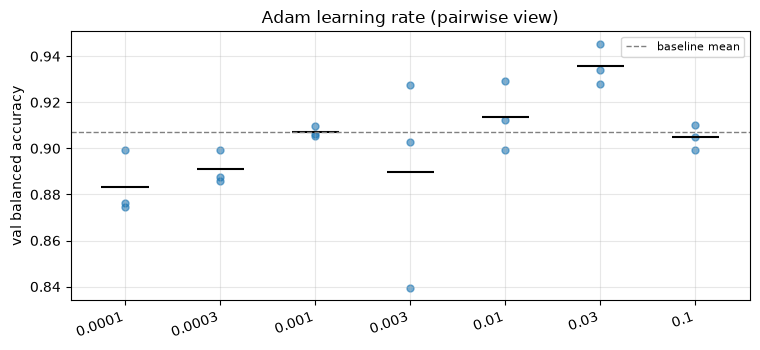

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
0.0001,0.8833,0.0137,3.0,-0.0237,0.0505,0.8743,0.9907,0.9097,83.6667,100244.0,0.5425
0.0003,0.8909,0.0073,3.0,-0.0161,0.0505,0.8826,0.9879,0.9097,72.3333,100244.0,0.5421
0.001,0.9070,0.0023,3.0,0.0000,0.0505,0.8986,0.9914,0.9271,62.3333,100244.0,0.5381
0.003,0.8898,0.0454,3.0,-0.0172,0.0505,0.8774,0.9932,0.9375,58.3333,100244.0,0.5426
0.01,0.9137,0.0150,3.0,0.0067,0.0505,0.9092,0.9911,0.9097,52.3333,100244.0,0.5428
0.03,0.9359,0.0089,3.0,0.0289,0.0505,0.9323,0.9932,0.9479,64.3333,100244.0,0.5436
0.1,0.9049,0.0055,3.0,-0.0021,0.0505,0.8915,0.9864,0.9271,52.6667,100244.0,0.5439


{'slope_per_decade': np.float64(0.0115), 'slope_ci': (np.float64(0.001992776452872375), np.float64(0.0210474905818136)), 'p_linear': np.float64(0.0204), 'p_quadratic': np.float64(0.4546), 'has_shape': True, 'best': 0.03, 'best_at_edge': False}


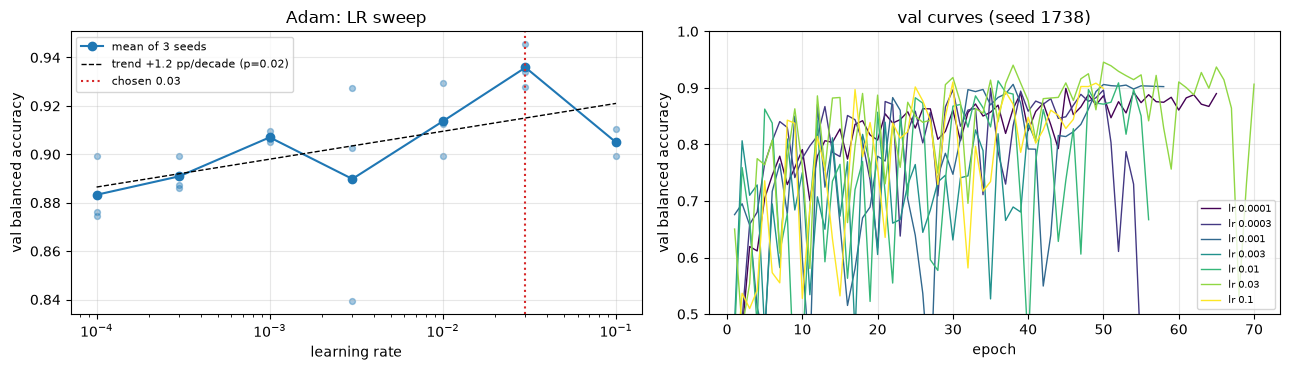

chosen lr: 0.03


In [3]:
def lr_sweep(cfg, lrs, prefix, base_runs=None, base_lr=None, max_ext=2):
    runs = {lr: (base_runs if lr == base_lr else run_seeds(replace(cfg, name=f"{prefix}_lr{lr:g}", lr=lr))) for lr in lrs}
    for _ in range(max_ext):
        ct = curve_test(runs)
        if not ct["best_at_edge"]:
            break
        lo, hi = min(runs), max(runs)
        step = lambda v, up: float(f"{v * (10 / 3 if (f'{v:e}'[0] == '3') == up else 3) ** (1 if up else -1):.1g}")  # 1-3-10 grid
        new = step(hi, True) if ct["best"] == hi else step(lo, False)
        runs[new] = run_seeds(replace(cfg, name=f"{prefix}_lr{new:g}", lr=new))
        runs = dict(sorted(runs.items()))
    return runs, curve_test(runs)

def show_sweep(runs, ct, title, ax):
    xs = sorted(runs); m = [ct["means"][x] for x in xs]
    for x in xs:
        ax.scatter([x] * len(runs[x]), [r["val"]["bal_acc"] for r in runs[x]], color="C0", alpha=0.4, s=18)
    ax.plot(xs, m, "o-", color="C0", label="mean of 3 seeds")
    xx = np.logspace(np.log10(xs[0]), np.log10(xs[-1]), 50)
    ax.plot(xx, np.mean(m) + ct["slope_per_decade"] * (np.log10(xx) - np.mean(np.log10(xs))), "k--", lw=1,
            label=f"trend {ct['slope_per_decade'] * 100:+.1f} pp/decade (p={ct['p_linear']:.1g})")
    ax.axvline(ct["best"], color="C3", ls=":", label=f"chosen {ct['best']:g}")
    ax.set(xscale="log", xlabel="learning rate", ylabel="val balanced accuracy", title=title); ax.grid(alpha=0.3); ax.legend(fontsize=8)

adam_runs, ct_adam = lr_sweep(CUR, [1e-4, 3e-4, 1e-3, 3e-3, 1e-2], "adam", BASE_RUNS, 1e-3)
t = compare({f"{k:g}": v for k, v in adam_runs.items()}, "0.001", "Adam learning rate (pairwise view)"); display(t)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in ct_adam.items() if k != "means"})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
show_sweep(adam_runs, ct_adam, "Adam: LR sweep", ax[0])
for (k, rs), c in zip(adam_runs.items(), plt.cm.viridis(np.linspace(0, 1, len(adam_runs)))):
    h = pd.DataFrame(rs[0]["history"]); ax[1].plot(h.epoch, h.val_bal_acc, color=c, label=f"lr {k:g}", lw=1)
ax[1].set(xlabel="epoch", ylabel="val balanced accuracy", title="val curves (seed 1738)", ylim=(0.5, 1)); ax[1].legend(fontsize=7); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
LR = float(ct_adam["best"])
CUR = replace(CUR, lr=LR); lr_runs = adam_runs; print("chosen lr:", LR)

In [4]:
# Is the trend an artefact of picking the best epoch? A higher LR could give a jumpier val curve, and the max of a
# jumpier curve is higher by luck. Check: jitter of the val curve after epoch 15, and the mean of the last 10 epochs
# (no selection at all).
rows = {}
for lr, rs in adam_runs.items():
    H = [pd.DataFrame(r["history"]).val_bal_acc.values for r in rs]
    rows[f"{lr:g}"] = {"best epoch (selected)": np.mean([r["val"]["bal_acc"] for r in rs]),
                       "mean of last 10 epochs": np.mean([h[-10:].mean() for h in H]),
                       "jitter (sd of epoch-to-epoch change)": np.mean([np.diff(h[15:]).std() for h in H])}
display(pd.DataFrame(rows).T.round(4))

,best epoch (selected),mean of last 10 epochs,jitter (sd of epoch-to-epoch change)
0.0001,0.8833,0.8484,0.0459
0.0003,0.8909,0.8300,0.1184
0.001,0.9070,0.8682,0.1392
0.003,0.8898,0.7512,0.1758
0.01,0.9137,0.7960,0.1794
0.03,0.9359,0.8709,0.1080
0.1,0.9049,0.8112,0.1194


_TODO lr_

## 2. Optimiser

{'slope_per_decade': np.float64(0.0175), 'slope_ci': (np.float64(0.0045760322867184), np.float64(0.030372472675368814)), 'p_linear': np.float64(0.0118), 'p_quadratic': np.float64(0.0276), 'has_shape': True, 'best': 0.1, 'best_at_edge': False}


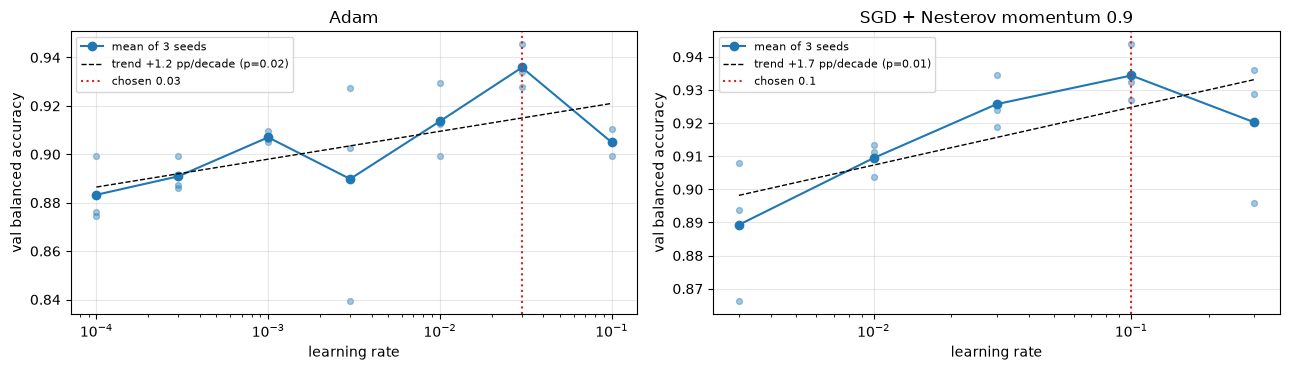

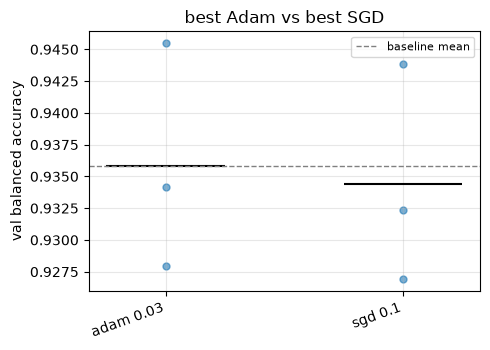

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
adam 0.03,0.9359,0.0089,3.0,0.0000,0.0505,0.9323,0.9932,0.9479,64.3333,100244.0,0.5436
sgd 0.1,0.9344,0.0086,3.0,-0.0015,0.0505,0.9317,0.9937,0.9236,90.0000,100244.0,0.5425


chosen optimiser: adam 0.03


In [5]:
sgd_runs, ct_sgd = lr_sweep(replace(CUR, optimizer="sgd"), [3e-3, 1e-2, 3e-2, 1e-1], "sgd")
sgd_runs = sgd_runs  # names: sgd_lr<lr>
SGD_LR = float(ct_sgd["best"])
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in ct_sgd.items() if k != "means"})
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
show_sweep(adam_runs, ct_adam, "Adam", ax[0]); show_sweep(sgd_runs, ct_sgd, "SGD + Nesterov momentum 0.9", ax[1])
plt.tight_layout(); plt.show()
cur_runs = lr_runs[LR]
t_sgd = compare({f"adam {LR:g}": cur_runs, f"sgd {SGD_LR:g}": sgd_runs[SGD_LR]}, f"adam {LR:g}", "best Adam vs best SGD"); display(t_sgd)
OPT = "sgd" if pick(t_sgd, f"adam {LR:g}") == f"sgd {SGD_LR:g}" else "adam"
if OPT == "sgd":
    CUR = replace(CUR, optimizer="sgd", lr=SGD_LR); cur_runs = sgd_runs[SGD_LR]
print("chosen optimiser:", OPT, CUR.lr)

_TODO opt_

## 3. Batch size

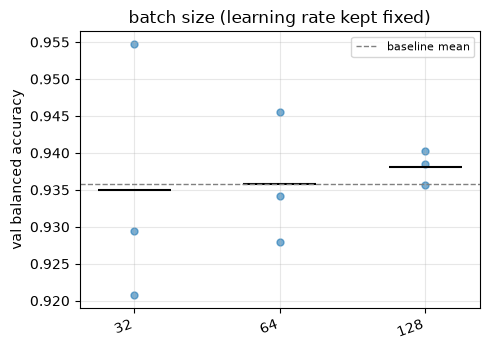

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
32,0.9350,0.0177,3.0,-0.0009,0.0505,0.9327,0.9948,0.9271,71.0000,100244.0,0.6490
64,0.9359,0.0089,3.0,0.0000,0.0505,0.9323,0.9932,0.9479,64.3333,100244.0,0.5436
128,0.9381,0.0023,3.0,0.0022,0.0505,0.9345,0.9944,0.9444,68.0000,100244.0,0.5201


{'slope_per_decade': np.float64(0.0052), 'slope_ci': (np.float64(-0.02897316616709565), np.float64(0.03934926220184441)), 'p_linear': np.float64(0.7301), 'p_quadratic': np.float64(0.9355), 'has_shape': False, 'best': 128, 'best_at_edge': True}
chosen batch size: 128


In [6]:
bs_runs = {str(bs): (cur_runs if bs == 64 else run_seeds(replace(CUR, name=f"{OPT}_lr{CUR.lr:g}_bs{bs}", batch_size=bs)))
           for bs in [32, 64, 128]}
t = compare(bs_runs, "64", "batch size (learning rate kept fixed)"); display(t)
ct_bs = curve_test({int(k): v for k, v in bs_runs.items()})
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in ct_bs.items() if k != "means"})
BS = int(ct_bs["best"]); CUR = replace(CUR, batch_size=BS); cur_runs = bs_runs[str(BS)]; print("chosen batch size:", BS)

_TODO bs_

## 4. Learning-rate schedule

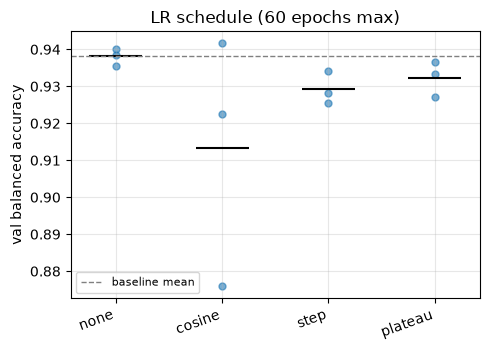

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
none,0.9381,0.0023,3.0,0.0000,0.0505,0.9345,0.9944,0.9444,68.0000,100244.0,0.5201
cosine,0.9133,0.0338,3.0,-0.0248,0.0505,0.8993,0.9918,0.9375,55.3333,100244.0,0.5200
step,0.9292,0.0044,3.0,-0.0089,0.0505,0.9236,0.9939,0.9306,62.6667,100244.0,0.5197
plateau,0.9324,0.0049,3.0,-0.0058,0.0505,0.9269,0.9943,0.9375,46.0000,100244.0,0.5201


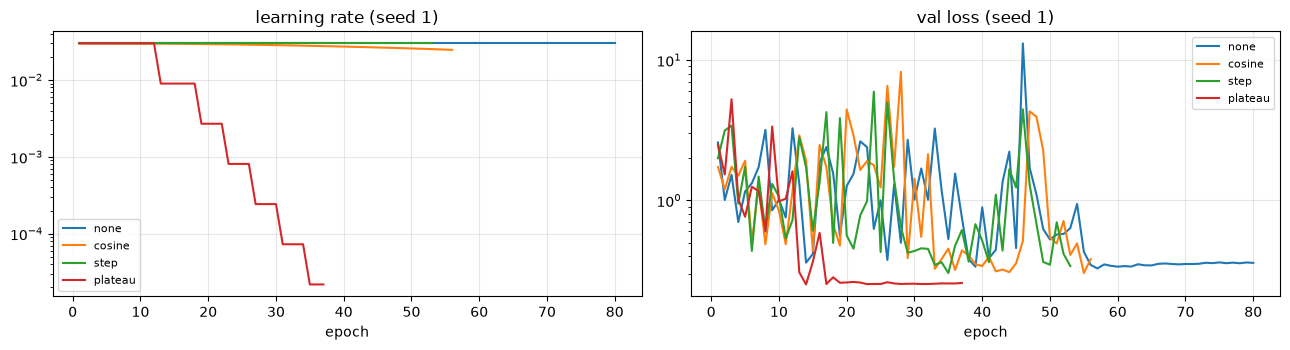

chosen schedule: none


In [7]:
tag = f"{OPT}_lr{CUR.lr:g}_bs{BS}"
sch = {"none": cur_runs, **{s: run_seeds(replace(CUR, name=f"{tag}_{s}", schedule=s)) for s in ["cosine", "step", "plateau"]}}
t = compare(sch, "none", "LR schedule (60 epochs max)"); display(t)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for k, rs in sch.items():
    h = pd.DataFrame(rs[0]["history"])
    ax[0].plot(h.epoch, h.lr, label=k); ax[1].plot(h.epoch, h.val_loss, label=k)
ax[0].set(yscale="log", title="learning rate (seed 1)", xlabel="epoch"); ax[1].set(yscale="log", title="val loss (seed 1)", xlabel="epoch")
for a in ax: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
SCHED = pick(t, "none"); CUR = replace(CUR, schedule=SCHED); cur_runs = sch[SCHED]; print("chosen schedule:", SCHED)

_TODO sched_

## 5. Loss function and class imbalance

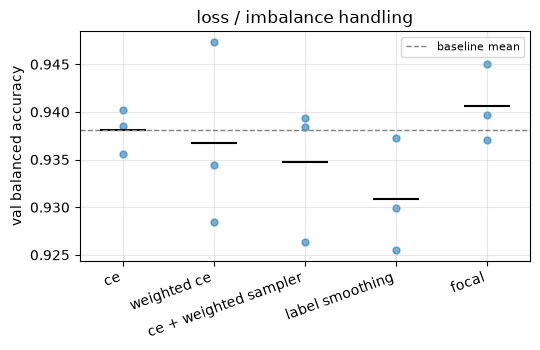

,bal_acc,sd,n,delta,needed,macro_f1,tumor_auc,no_tumor_rec,epochs,params,s/ep
ce,0.9381,0.0023,3.0,0.0000,0.0505,0.9345,0.9944,0.9444,68.0000,100244.0,0.5201
weighted ce,0.9368,0.0097,3.0,-0.0014,0.0505,0.9341,0.9958,0.9271,87.3333,100244.0,0.5195
ce + weighted sampler,0.9347,0.0072,3.0,-0.0034,0.0505,0.9298,0.9950,0.9514,70.0000,100244.0,0.5185
label smoothing,0.9309,0.0059,3.0,-0.0072,0.0505,0.9232,0.9947,0.9340,51.6667,100244.0,0.5211
focal,0.9406,0.0041,3.0,0.0025,0.0505,0.9321,0.9945,0.9618,77.3333,100244.0,0.5208


mean per-class recall:


,glioma,meningioma,no_tumor,pituitary
ce,0.947,0.895,0.944,0.966
weighted ce,0.935,0.904,0.927,0.981
ce + weighted sampler,0.937,0.884,0.951,0.966
label smoothing,0.906,0.904,0.934,0.979
focal,0.915,0.921,0.962,0.965


chosen: focal


In [8]:
tag = f"{OPT}_lr{CUR.lr:g}_bs{BS}_{SCHED}"
loss = {"ce": cur_runs,
        "weighted ce": run_seeds(replace(CUR, name=f"{tag}_wce", loss="weighted_ce")),
        "ce + weighted sampler": run_seeds(replace(CUR, name=f"{tag}_sampler", sampler="weighted")),
        "label smoothing": run_seeds(replace(CUR, name=f"{tag}_ls", loss="label_smoothing")),
        "focal": run_seeds(replace(CUR, name=f"{tag}_focal", loss="focal"))}
t = compare(loss, "ce", "loss / imbalance handling"); display(t)
rec = pd.DataFrame({k: pd.DataFrame([r["val"]["recall"] for r in rs]).mean() for k, rs in loss.items()}).T
print("mean per-class recall:"); display(rec.round(3))
LOSS = pick(t, "ce")
key = {"ce": {}, "weighted ce": {"loss": "weighted_ce"}, "ce + weighted sampler": {"sampler": "weighted"},
       "label smoothing": {"loss": "label_smoothing"}, "focal": {"loss": "focal"}}[LOSS]
CUR = replace(CUR, **key); print("chosen:", LOSS)

_TODO loss_

## Decisions

_TODO summary_

In [9]:
OPTIM = dict(optimizer=CUR.optimizer, lr=CUR.lr, batch_size=CUR.batch_size, schedule=CUR.schedule,
             loss=CUR.loss, sampler=CUR.sampler)
_ = (ARTIFACTS / "optim.json").write_text(json.dumps(OPTIM))
print(OPTIM, "-> mean val bal. acc", round(log_progress("c6 optimisation", loss[LOSS]), 4))

{'optimizer': 'adam', 'lr': 0.03, 'batch_size': 128, 'schedule': 'none', 'loss': 'focal', 'sampler': 'none'} -> mean val bal. acc 0.9406
